# KyberSwap Aggregator: volume, chain mix, take rate and a 4-week forecast

**Author:** Misha Parekh · November 2026

A short, reproducible look at KyberSwap Aggregator's routed volume, using DefiLlama's free public API:
`api.llama.fi/summary/aggregators/kyberswap-aggregator?dataType=dailyVolume` (daily volume, total and by chain) and
`api.llama.fi/summary/fees/kyberswap-aggregator?dataType=dailyFees` (daily fees). The raw JSON is in `data/`.

1. How volume has moved since 2024
2. Which chains are gaining or losing share
3. Take rate: fees per dollar of volume
4. The weekly pattern
5. A 4-week forecast, chosen by a walk-forward backtest against simple baselines

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
A = json.load(open("data/kyberswap_volume.json")); F = json.load(open("data/kyberswap_fees.json"))
to_s = lambda pts: pd.Series({pd.Timestamp(t, unit="s"): float(v) for t, v in pts}).sort_index()
vol, fee = to_s(A["totalDataChart"]), to_s(F["totalDataChart"])
vol, fee = vol.iloc[:-1], fee.iloc[:-1]          # drop the last day, which may be partial
br = pd.DataFrame([(pd.Timestamp(t, unit="s"), ch, sum(v.values())) for t, d in A["totalDataChartBreakdown"] for ch, v in d.items()],
                  columns=["date", "chain", "vol"])
br = br[br.date <= vol.index.max()]
END = vol.index.max()
print(f"Volume: {vol.index.min():%d %b %Y} to {END:%d %b %Y} ({len(vol)} days, {pd.date_range(vol.index.min(), END).difference(vol.index).size} missing); "
      f"fees from {fee.index.min():%d %b %Y}; {br.chain.nunique()} chains")

Volume: 01 Jan 2024 to 10 Nov 2026 (1040 days, 5 missing); fees from 15 Jun 2024; 26 chains


## 1. Volume since 2024

Last 90 days: $20.4bn vs $40.4bn in the same 90 days a year earlier (-49%)
Five largest days ($m):
2025-09-25    2110.0
2025-09-26    1449.0
2026-04-19     792.0
2025-09-23     781.0
2025-09-22     752.0


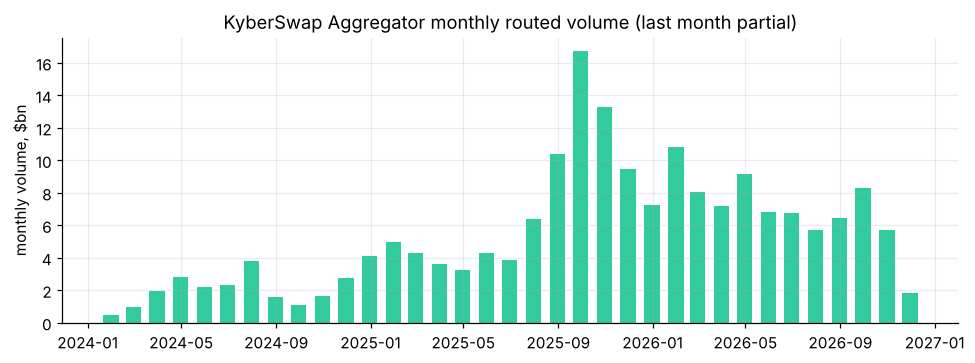

In [2]:
m = vol.resample("ME").sum() / 1e9
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(m.index, m.values, width=20, color="#31CB9E")
ax.set_ylabel("monthly volume, $bn"); ax.set_title("KyberSwap Aggregator monthly routed volume (last month partial)"); plt.tight_layout()
w90, y90 = vol[vol.index > END - pd.Timedelta(days=90)].sum(), vol[(vol.index <= END - pd.Timedelta(days=365)) & (vol.index > END - pd.Timedelta(days=455))].sum()
print(f"Last 90 days: ${w90/1e9:.1f}bn vs ${y90/1e9:.1f}bn in the same 90 days a year earlier ({w90/y90-1:+.0%})")
print("Five largest days ($m):"); print((vol.nlargest(5) / 1e6).round(0).to_string())

## 2. Chain mix

Share of volume in the last 90 days compared with the same 90 days a year earlier.

In [3]:
cut0, cut1 = END - pd.Timedelta(days=90), END - pd.Timedelta(days=365)
now = br[br.date > cut0].groupby("chain").vol.sum()
ago = br[(br.date <= cut1) & (br.date > cut1 - pd.Timedelta(days=90))].groupby("chain").vol.sum()
t = pd.DataFrame({"last 90d $bn": now / 1e9, "year earlier $bn": ago / 1e9}).fillna(0)
t["share now %"] = 100 * t["last 90d $bn"] / t["last 90d $bn"].sum(); t["share then %"] = 100 * t["year earlier $bn"] / t["year earlier $bn"].sum()
t["change, pp"] = t["share now %"] - t["share then %"]
t = t.sort_values("last 90d $bn", ascending=False)
hhi = lambda s: ((s / s.sum()) ** 2).sum()
print(f"Concentration (HHI, 0-1): now {hhi(now):.2f}, a year earlier {hhi(ago):.2f}")
t.head(12).round(2)

Concentration (HHI, 0-1): now 0.30, a year earlier 0.26


,last 90d $bn,year earlier $bn,share now %,share then %,"change, pp"
chain,,,,,
Ethereum,10.43,18.85,51.08,46.67,4.41
Robinhood Chain,2.95,0.00,14.45,0.00,14.45
Base,2.23,3.43,10.90,8.50,2.39
BSC,1.46,6.17,7.13,15.27,-8.14
Avalanche,0.79,1.99,3.89,4.94,-1.05
Polygon,0.66,0.73,3.24,1.80,1.44
Arbitrum,0.64,2.08,3.14,5.15,-2.01
Hyperliquid L1,0.49,0.97,2.41,2.39,0.02
Monad,0.38,0.00,1.86,0.00,1.86


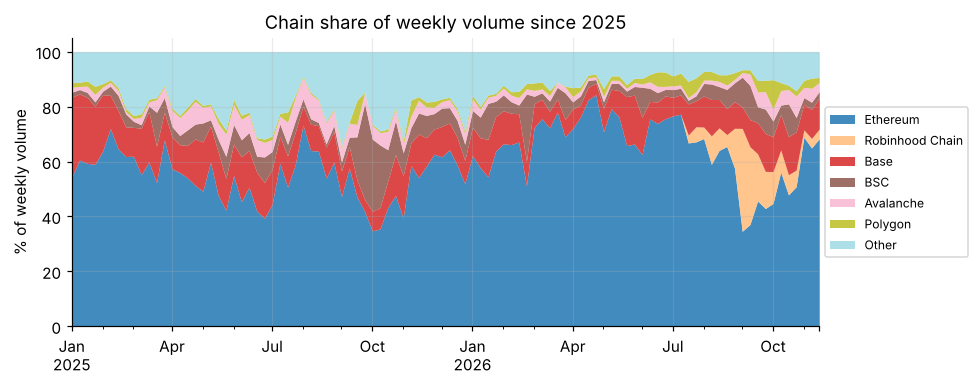

In [4]:
top = t.index[:6]
wk = br.assign(c=br.chain.where(br.chain.isin(top), "Other")).groupby([pd.Grouper(key="date", freq="W"), "c"]).vol.sum().unstack().fillna(0)
wk = wk[wk.index >= "2025-01-01"]; sh = wk.div(wk.sum(1), axis=0) * 100
ax = sh[list(top) + ["Other"]].plot.area(figsize=(9, 3.6), linewidth=0, alpha=.85, colormap="tab20")
ax.set_ylabel("% of weekly volume"); ax.set_xlabel(""); ax.set_title("Chain share of weekly volume since 2025"); ax.legend(loc="center left", bbox_to_anchor=(1, .5), fontsize=8); plt.tight_layout()

## 3. Take rate

Fees retained by KyberSwap divided by routed volume, on a rolling 30-day basis, in basis points (1 bp = 0.01%).

Quarterly average take rate (bps):
2024-09-30     2.28
2024-12-31    10.84
2025-03-31     5.61
2025-06-30     3.72
2025-09-30     1.62
2025-12-31     1.02
2026-03-31     0.64
2026-06-30     1.27
2026-09-30     0.85
2026-12-31     0.84
Freq: QE-DEC
Fee series: 24 missing days since it starts; windows containing a gap are left out, which is why the line jumps.
Last 30 days: fees $559k on $5.43bn volume = 1.03 bps


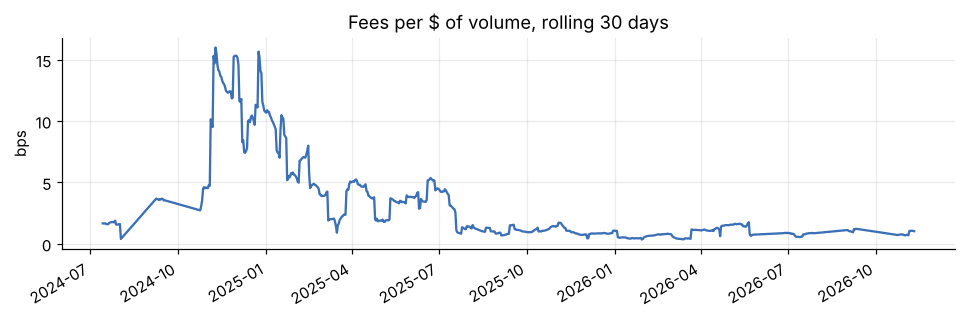

In [5]:
f30 = fee.reindex(vol.index).rolling(30).sum(); v30 = vol.rolling(30).sum()
tr = (f30 / v30 * 1e4).dropna()
ax = tr.plot(figsize=(9, 3), color="#3B6FB6"); ax.set_ylabel("bps"); ax.set_title("Fees per $ of volume, rolling 30 days"); plt.tight_layout()
q = tr.resample("QE").mean().round(2); print("Quarterly average take rate (bps):"); print(q.to_string())
print(f"Fee series: {fee.reindex(vol.index[vol.index >= fee.index.min()]).isna().sum()} missing days since it starts; windows containing a gap are left out, which is why the line jumps.")
print(f"Last 30 days: fees ${f30.iloc[-1]/1e3:,.0f}k on ${v30.iloc[-1]/1e9:.2f}bn volume = {tr.iloc[-1]:.2f} bps")

## 4. Weekly pattern

In [6]:
lv = np.log(vol[vol.index >= "2025-01-01"])
dow = (lv.groupby(lv.index.dayofweek).mean() - lv.mean())
eff = (np.exp(dow) - 1) * 100; eff.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wkend = np.exp(lv[lv.index.dayofweek >= 5].mean() - lv[lv.index.dayofweek < 5].mean()) - 1
print(f"Weekend days run {wkend:.0%} against weekdays (geometric mean, since 2025)")
eff.round(1).rename("% vs average day").to_frame()

Weekend days run -36% against weekdays (geometric mean, since 2025)


,% vs average day
Mon,7.7
Tue,13.6
Wed,12.1
Thu,20.0
Fri,16.2
Sat,-27.6
Sun,-27.8


## 5. A 4-week forecast

Daily volume is heavy-tailed, so models work on log volume. Three candidates:
* **Seasonal naive:** each day equals the same weekday last week.
* **28-day mean:** the average log volume of the last four weeks, plus the weekday effect.
* **ETS:** exponential smoothing on log volume with a weekly seasonal term (statsmodels `ETSModel`, additive error and seasonality, no trend).

Each model is scored by a **walk-forward backtest**: 12 forecast origins, one week apart, each forecasting the next 28 days using only data before the origin.
The error metric is MAPE on daily dollar volume.

In [7]:
y = np.log(vol[vol.index >= "2025-01-01"]).asfreq("D").interpolate()
def f_snaive(h, tr): return np.tile(tr.iloc[-7:].values, h // 7 + 1)[:h]
def f_mean(h, tr):
    base = tr.iloc[-28:].mean(); d = (tr.iloc[-91:].groupby(tr.iloc[-91:].index.dayofweek).mean() - tr.iloc[-91:].mean())
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h); return base + d.reindex(idx.dayofweek).values
def f_ets(h, tr): return ETSModel(tr, error="add", trend=None, seasonal="add", seasonal_periods=7).fit(disp=False).forecast(h).values
H, res = 28, {"Seasonal naive": [], "28-day mean": [], "ETS": []}
for k in range(12, 0, -1):
    o = len(y) - H - 7 * (k - 1); tr, te = y.iloc[:o], np.exp(y.iloc[o:o + H].values)
    for name, fn in [("Seasonal naive", f_snaive), ("28-day mean", f_mean), ("ETS", f_ets)]:
        res[name].append(np.mean(np.abs(np.exp(fn(H, tr)) - te) / te) * 100)
bt = pd.DataFrame(res); print("Walk-forward MAPE over 12 origins (%):"); print(bt.describe().loc[["mean", "50%", "min", "max"]].round(1))

Walk-forward MAPE over 12 origins (%):
      Seasonal naive  28-day mean   ETS
mean            39.8         41.2  35.3
50%             36.8         39.6  33.6
min             21.1         17.1  19.8
max             69.1         72.5  57.0


Best model by mean MAPE: ETS
Forecast weekly volume ($bn): [1.17, 1.17, 1.17, 1.17]
4-week total: $4.7bn (median path; the interval is wide because daily volume is volatile)


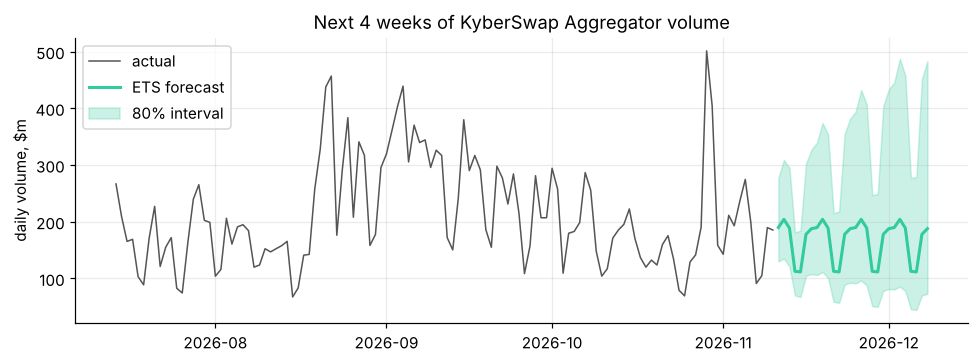

In [8]:
best = bt.mean().idxmin(); print("Best model by mean MAPE:", best)
fit = ETSModel(y, error="add", trend=None, seasonal="add", seasonal_periods=7).fit(disp=False)
pr = fit.get_prediction(start=len(y), end=len(y) + H - 1).summary_frame(alpha=0.2)
pr.index = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=H)
fc = np.exp(pr) / 1e6
hist = np.exp(y.iloc[-120:]) / 1e6
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(hist.index, hist.values, color="#555", lw=1, label="actual")
ax.plot(fc.index, fc["mean"], color="#31CB9E", lw=2, label="ETS forecast")
ax.fill_between(fc.index, fc["pi_lower"], fc["pi_upper"], color="#31CB9E", alpha=.25, label="80% interval")
ax.set_ylabel("daily volume, $m"); ax.set_title("Next 4 weeks of KyberSwap Aggregator volume"); ax.legend(); plt.tight_layout()
wk_tot = fc["mean"].groupby(np.arange(H) // 7).sum()
print("Forecast weekly volume ($bn):", (wk_tot / 1e3).round(2).tolist())
print(f"4-week total: ${fc['mean'].sum()/1e3:.1f}bn (median path; the interval is wide because daily volume is volatile)")

## Notes and limitations
* DefiLlama's adapter reports volume routed through KyberSwap's aggregator; its methodology is linked from the DefiLlama page. Chain labels and totals are as DefiLlama reports them.
* The forecast is a statistical baseline: it knows nothing about launches, incentives or market moves, and its 80% interval is for planning, not prediction of individual days.
* The fee series has missing days; rolling windows that contain a gap are left out. The very high take rate around December 2024 reflects unusually high reported fees that month.
* Fees are the aggregator fees DefiLlama counts as retained by KyberSwap; the take rate here is fees divided by that routed volume.

**Possible next steps with KyberSwap's own data:** per-route and per-token volume, user cohorts and retention, and a model that uses market-wide DEX volume as a leading signal.